In [1]:
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr
import pyremo as pr
import cmaps
import glob
import os
#from REMO2020_mod import  open_mfdataset, domainclass, plotclass, remo_plotter_2mods
from openpyxl import load_workbook
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import matplotlib.patches as mpatches
from REMO2020TEB_mod import flip, modelclass_cities, prepare_midas_data, prepare_remo_to_umask_seas, diurnal_metrics, df_to_latex_categ
os.environ['PATH'] = '/work/ch0636/g300096/Python/envs/kernelR2020TEB/bin:' + os.environ['PATH']

/work/ch0636/g300096/Python/envs/kernelR2020TEB/lib/python3.10/site-packages/pyremo/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
from dask.distributed import Client, progress
import dask
dask.config.set({'temporary_directory': '/scratch/g/g300096/dask/tmp'})
client = Client()
client

/work/ch0636/g300096/Python/envs/kernelR2020TEB/lib/python3.10/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 41687 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/g300096/levante-spawner-preset//proxy/41687/status,
Dashboard: /user/g300096/levante-spawner-preset//proxy/41687/status,Workers: 16
Total threads: 256,Total memory: 235.37 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:37641,Workers: 0
Dashboard: /user/g300096/levante-spawner-preset//proxy/41687/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34329,Total threads: 16
Dashboard: /user/g300096/levante-spawner-preset//proxy/45961/status,Memory: 14.71 GiB
Nanny: tcp://127.0.0.1:39915,


In [3]:
# give figure path
figpath = './figures/'

In [4]:
# Give the quantiles to be calculated (must inlcude 0.5)
quantiles = np.array([0.05,0.25,0.5,0.75,0.95])

In [5]:
# if we want to replace median with mean
lreplace_median=True

In [6]:
# St James' Park urban coordinates
station_urb = "St. James's Park"
station_id_urb = "00697"
station_lat_urb = 51.50425
station_lon_urb = -0.12948

# Wisley rural cite coordinates
station_rur = "Wisley"
station_id_rur = "00719"
station_lat_rur = 51.31027
station_lon_rur = -0.47478

In [7]:
# Measurement data for UK
midas_datapath = "/work/ch0636/g300096/data/TEB_analysis/station_data/MIDAS/"
midas_filename = "midas-open_uk-hourly-weather-obs_dv-202507_greater-london_00697_london-st-jamess-park_qcv-1_2020.csv"
midas_urban, midas_urban_raw = prepare_midas_data(midas_datapath,midas_filename,"air_temperature",quantiles,lreplace_median,addc=273.15)
midas_filename = "midas-open_uk-hourly-weather-obs_dv-202507_surrey_00719_wisley_qcv-1_2020.csv"
midas_rural, midas_rural_raw = prepare_midas_data(midas_datapath,midas_filename,"air_temperature",quantiles,lreplace_median,addc=273.15)

Dropped 1 rows with invalid time values (NaT).
Data sorted by time. Remaining rows: 8779
Dropped 1 rows with invalid time values (NaT).
Data sorted by time. Remaining rows: 8780


In [8]:
# Midas uhi
midas_uhi_raw = (midas_urban_raw-midas_rural_raw)["air_temperature"].groupby(["season", "hour"])
midas_uhi = midas_uhi_raw.quantile(quantiles, dim='time').compute()
if (lreplace_median):
    midas_uhi.loc[dict(quantile=0.5)] = midas_uhi_raw.mean("time").compute()

In [9]:
# read in REMO hourly data
remo_datap = "/work/ch0636/g300096/results/TEB/post-processed"

In [10]:
## read in urban/rural mask
urb_rur_remo_mask_hr = xr.open_dataset("./data_in/model_data/REMO_static/urmask_London-ALPX-3_urclim_masks_fx.nc").compute()
urb_rur_remo_mask_lr = xr.open_dataset("./data_in/model_data/REMO_static/urmask_London-EUR-11_urclim_masks_fx.nc").compute()

In [11]:
# define the runs to be analysed
modelruns =[] # init

# 
modelruns.append(modelclass_cities("036047","REMO2020 TEB","ECOSG_LCZ",'b-','0.0275'))
modelruns.append(modelclass_cities("036048","REMO2020 TEB iMOVE","LANDMATE",'r-','0.0275'))
modelruns.append(modelclass_cities("036049","REMO2020","GLCC",'c-','0.0275'))
modelruns.append(modelclass_cities("036043","REMO2020 TEB","ECOSG_LCZ",'b--','0.11'))
modelruns.append(modelclass_cities("036044","REMO2020 TEB iMOVE","LANDMATE",'r--','0.11'))
modelruns.append(modelclass_cities("036041","REMO2020","GLCC",'c--','0.11'))

In [12]:
## read in data
for obj in modelruns:
    if (obj.reso == '0.0275'):
        obj.rawdata = xr.merge([pr.parse_dates(xr.open_dataset(remo_datap+"/"+obj.userexp+"_postpro_1h_2020.nc")),urb_rur_remo_mask_hr[obj.maskname]], compat="override", join="override")
    elif (obj.reso == '0.11'):
        obj.rawdata = xr.merge([pr.parse_dates(xr.open_dataset(remo_datap+"/"+obj.userexp+"_postpro_1h_2020.nc")),urb_rur_remo_mask_lr[obj.maskname]], compat="override", join="override")
    # Shift time by 30 minutes backwards (REMO specific)
    obj.rawdata = obj.rawdata.assign_coords(time=obj.rawdata.time - pd.Timedelta('60min'))
    obj.rawdata = obj.rawdata.assign_coords(
        season=obj.rawdata.time.dt.season,
        hour=obj.rawdata.time.dt.hour
    )

In [13]:
## prepare wanted variable
varname="TEMP2"
for obj in modelruns:
    obj.vardata = prepare_remo_to_umask_seas(obj.rawdata,obj.maskname,varname,lreplace_median,quantiles,luhi=True)

In [14]:
# Define the order of seasons to be used (also when plotting)
seasons = ["DJF","MAM","JJA","SON"]

In [15]:
rows = []
for seas in seasons:
    obs = midas_uhi.sel(season=seas).sel(quantile=0.5).values
    for obj in modelruns:
        mod = obj.vardata.uhi.sel(season=seas).sel(quantile=0.5).values
        metrics = diurnal_metrics(obs, mod)
        metrics["Season"] = seas
        metrics["Model"] = obj.runame
        metrics["Resolution"] = obj.reso
        rows.append(metrics)

res_diu = pd.DataFrame(rows)
res_diu = res_diu[["Model", "Resolution", "Season"] + [col for col in res_diu.columns 
                               if col not in ["Model", "Resolution",  "Season"]]]

In [16]:
latex_code = df_to_latex_categ(res_diu)
print(latex_code)

\begin{table*}
\caption{Seasonal diurnal-cycle metrics}
\label{tab:metrics}
\begin{tabular}{l c c r r r r r}
\hline
Model & Resolution & Season & RMSE & MAE & Bias & Correlation & Amplitude Error \\
\hline
REMO2020 TEB & 0.0275 & DJF & 1.08 & \underline{1.07} & \underline{1.07} & \textbf{0.90} & \textbf{-0.09} \\
REMO2020 TEB iMOVE & 0.0275 & DJF & 1.09 & \underline{1.08} & \underline{1.08} & \textbf{0.90} & \textbf{-0.06} \\
REMO2020 & 0.0275 & DJF & 1.01 & 0.90 & \underline{-0.82} & \underline{-0.80} & 0.61 \\
REMO2020 TEB & 0.11 & DJF & \textbf{0.55} & 0.52 & 0.52 & 0.72 & \textbf{-0.48} \\
REMO2020 TEB iMOVE & 0.11 & DJF & \textbf{0.58} & 0.56 & 0.56 & 0.74 & \textbf{-0.38} \\
REMO2020 & 0.11 & DJF & 0.71 & 0.68 & -0.68 & \underline{-0.37} & -0.57 \\
REMO2020 TEB & 0.0275 & MAM & 1.04 & 0.88 & \underline{0.88} & 0.77 & \textbf{0.00} \\
REMO2020 TEB iMOVE & 0.0275 & MAM & 0.99 & 0.85 & \underline{0.85} & 0.79 & \textbf{-0.36} \\
REMO2020 & 0.0275 & MAM & \underline{1.99} & \underlin

In [17]:
# select plotted quantiles for shading (and 1-q)
ploquan = [0.05,0.25]

### Prepare some common plotting configs

In [18]:
# Reset and set rcParams
mpl.rcParams.update(mpl.rcParamsDefault)
#plt.rcParams["figure.figsize"] = (25, 25)
plt.rcParams["figure.subplot.wspace"] = 0.3
plt.rcParams["axes.titlesize"] = 26
plt.rcParams['axes.labelsize'] = 22
plt.rcParams["xtick.top"] = True
plt.rcParams["xtick.labeltop"] = False
plt.rcParams["xtick.bottom"] = True
plt.rcParams["xtick.labelbottom"] = True
plt.rcParams["ytick.left"] = True
plt.rcParams["ytick.labelleft"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["ytick.labelright"] = False
plt.rcParams['lines.markersize'] = 10
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.rc('xtick', labelsize=24) 
plt.rc('ytick', labelsize=24) 
plt.rc('legend', fontsize=22)

# Prepare temperature plots

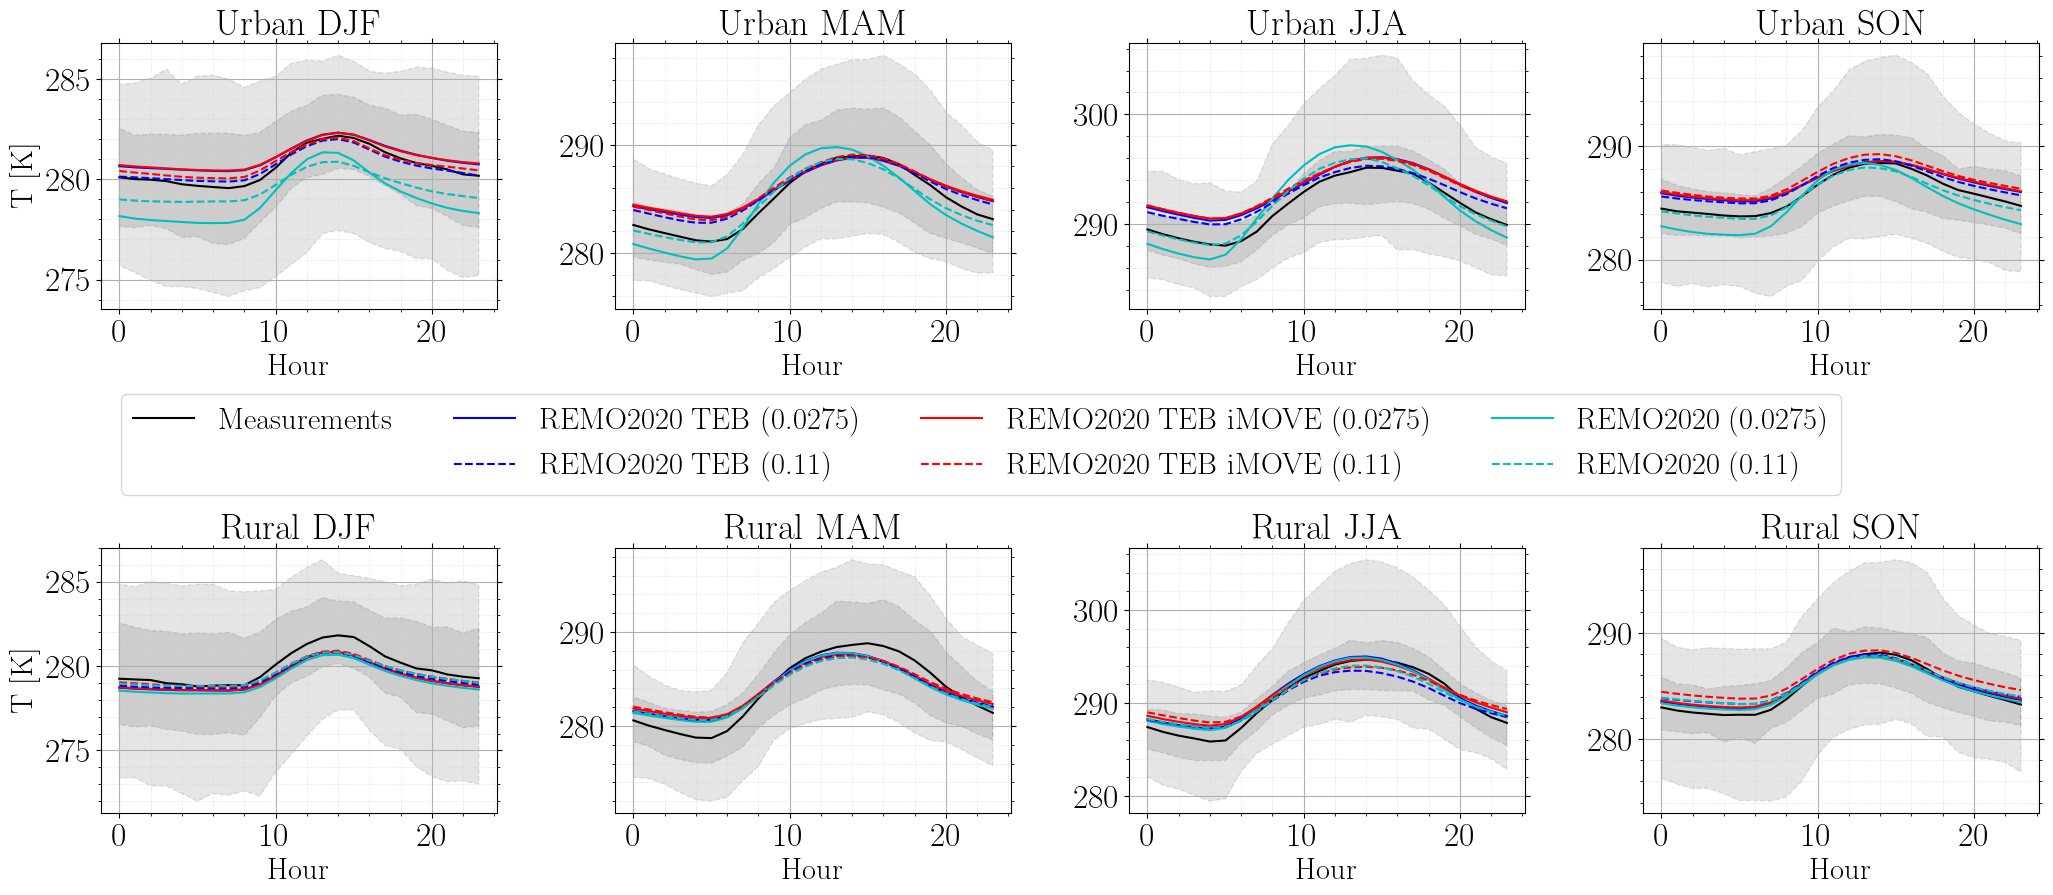

In [19]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.9
# Create subplots: 2 rows, 4 columns
fig, ax = plt.subplots(2, 4, figsize=(25, 10))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    ax[ind].grid() # make grid and modify it
    ax[ind].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
    ax[ind].minorticks_on() # use minor ticks
    ax[ind + len(seasons)].grid() # make grid and modify it
    ax[ind + len(seasons)].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
    ax[ind + len(seasons)].minorticks_on() # use minor ticks
    # Urban plot
    ax[ind].plot(midas_urban.hour.values,
                 midas_urban.sel(season=seas).sel(quantile=0.5).values,
                 'k-', label="Measurements")
    for qq in ploquan:
        ax[ind].fill_between(midas_urban.hour.values,
                            midas_urban.sel(season=seas).sel(quantile=qq).values, midas_urban.sel(season=seas).sel(quantile=1.0-qq).values,
                            color='k', alpha=0.1, linewidth=1, linestyle = '--')
    
    for obj in modelruns:
        ax[ind].plot(obj.vardata.hour.values,
                     obj.vardata.urban.sel(season=seas).sel(quantile=0.5).values,
                     obj.plstyle, label=obj.runame+" ("+obj.reso+")")

#        for qq in ploquan:
#            ax[ind].fill_between(obj.vardata.hour.values,
#                                obj.vardata.urban.sel(season=seas).sel(quantile=qq).values, obj.vardata.urban.sel(season=seas).sel(quantile=1.0-qq).values,
#                                color=obj.plstyle[0], alpha=0.1, linewidth=1, linestyle = '--')
    ax[ind].set_title(f"Urban {seas}")
    ax[ind].set_xlabel("Hour")
    if seas == "DJF":
        ax[ind].set_ylabel("T [K]")
        # flip and insert one empty string
        handles, labels = ax[ind].get_legend_handles_labels()
        empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
        handles.insert(ncol, empty_patch)
        labels.insert(ncol,'')
        ax[ind].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.05, -0.7), ncol=ncol, frameon=True)
    
    # Rural plot
    ax[ind + len(seasons)].plot(midas_rural.hour.values,
                                midas_rural.sel(season=seas).sel(quantile=0.5).values,
                                'k-', label="Measurements")
    for qq in ploquan:
        ax[ind + len(seasons)].fill_between(midas_rural.hour.values,
                            midas_rural.sel(season=seas).sel(quantile=qq).values, midas_rural.sel(season=seas).sel(quantile=1.0-qq).values,
                            color='k', alpha=0.1, linewidth=1, linestyle = '--')
    for obj in modelruns:
        ax[ind + len(seasons)].plot(obj.vardata.hour.values,
                                    obj.vardata.rural.sel(season=seas).sel(quantile=0.5).values,
                                    obj.plstyle, label=obj.runame+" ("+obj.reso+")")
#        for qq in ploquan:
#            ax[ind + len(seasons)].fill_between(obj.vardata.hour.values,
#                                obj.vardata.rural.sel(season=seas).sel(quantile=qq).values, obj.vardata.rural.sel(season=seas).sel(quantile=1.0-qq).values,
#                                color=obj.plstyle[0], alpha=0.1, linewidth=1, linestyle = '--') 
    ax[ind + len(seasons)].set_title(f"Rural {seas}")
    ax[ind + len(seasons)].set_xlabel("Hour")
    if seas == "DJF":
        ax[ind + len(seasons)].set_ylabel("T [K]")
    # increase counter
    ind += 1
    
plt.savefig(figpath + 'Midas_seas_UrbRur_urmask_temperatures.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()

### Prepare UHI plots

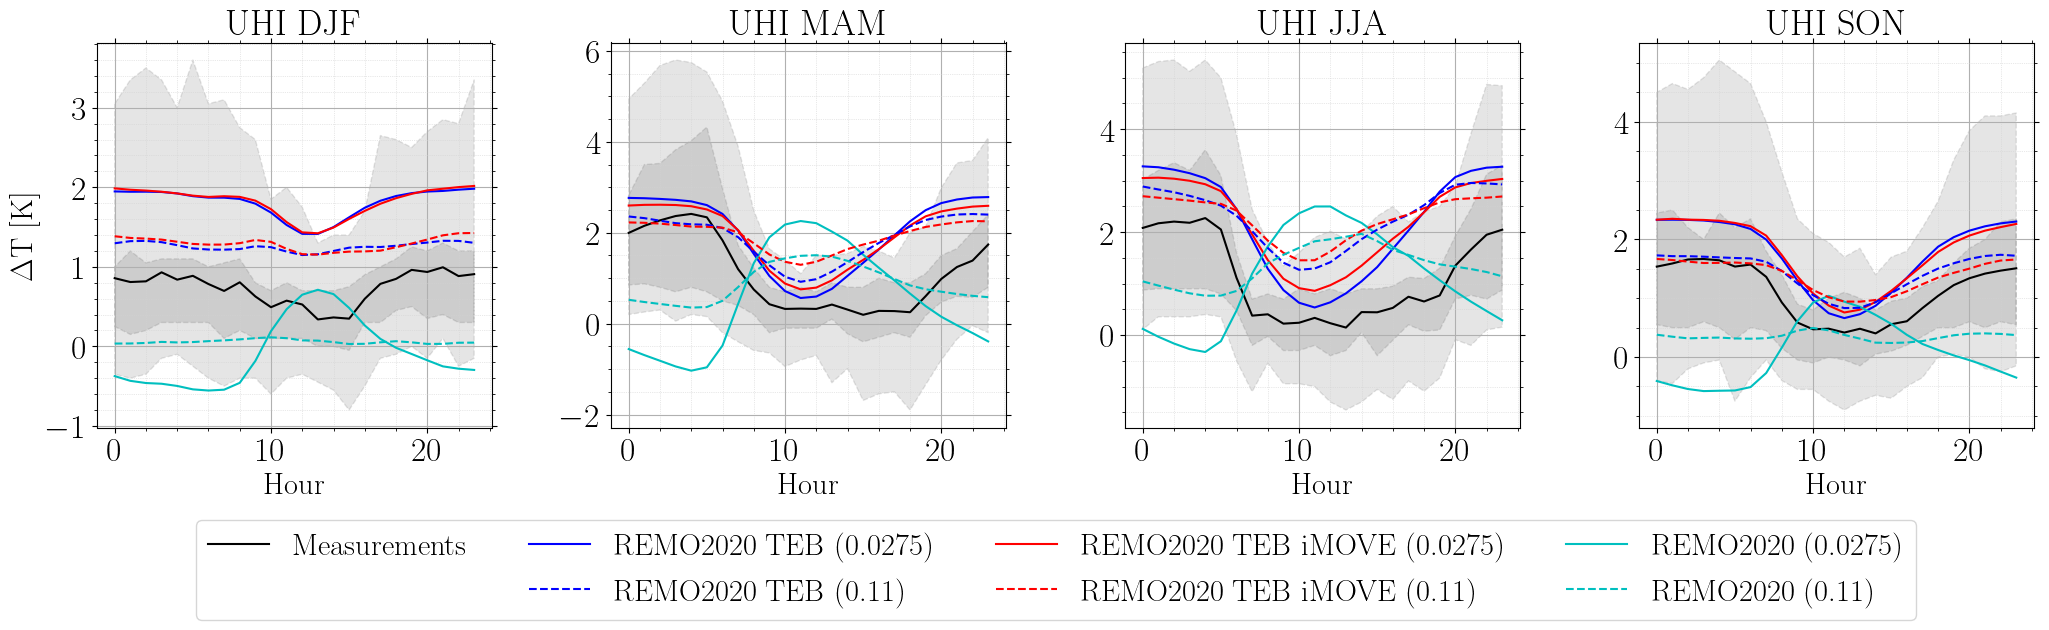

In [20]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.7
# Create subplots: 1 row, 4 columns
fig, ax = plt.subplots(1, 4, figsize=(25, 5))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    ax[ind].grid() # make grid and modify it
    ax[ind].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
    ax[ind].minorticks_on() # use minor ticks
    # UHI plot
    ax[ind].plot(midas_uhi.hour.values,
                 midas_uhi.sel(season=seas).sel(quantile=0.5).values,
                 'k-', label="Measurements")
    for qq in ploquan:
        ax[ind].fill_between(midas_uhi.hour.values,
                            midas_uhi.sel(season=seas).sel(quantile=qq).values, midas_uhi.sel(season=seas).sel(quantile=1.0-qq).values,
                            color='k', alpha=0.1, linewidth=1, linestyle = '--')
    
    for obj in modelruns:
        ax[ind].plot(obj.vardata.hour.values,
                     obj.vardata.uhi.sel(season=seas).sel(quantile=0.5).values,
                     obj.plstyle, label=obj.runame+" ("+obj.reso+")")
#        for qq in ploquan:
#            ax[ind].fill_between(obj.vardata.hour.values,
#                                obj.vardata.uhi.sel(season=seas).sel(quantile=qq).values, obj.vardata.uhi.sel(season=seas).sel(quantile=1.0-qq).values,
#                                color=obj.plstyle[0], alpha=0.1, linewidth=1, linestyle = '--')
    ax[ind].set_title(f"UHI {seas}")
    ax[ind].set_xlabel("Hour")
    if seas == "DJF":
        ax[ind].set_ylabel("$\Delta$T [K]")
        # flip and insert one empty string
        handles, labels = ax[ind].get_legend_handles_labels()
        empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
        handles.insert(ncol, empty_patch)
        labels.insert(ncol,'')
        ax[ind].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.25, -0.5), ncol=ncol, frameon=True)
    # increase counter
    ind += 1

plt.savefig(figpath + 'Midas_urmask_seas_UHI.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()